# Heart Disease Health Indicators - EDA & Predictive Modeling
An end-to-end Machine Learning project to predict heart disease or heart attacks using the CDC's BRFSS 2015 dataset.

### Project Overview:
- **Dataset**: CDC BRFSS 2015 survey responses (253,680 records, 22 columns)
- **Target**: `HeartDiseaseorAttack` (Binary: 0 = No, 1 = Yes)
- **Goal**: Build a classifier that identifies individuals at high risk of heart disease or attack, prioritizing **Recall** because in healthcare, missing a positive case (False Negative) is much more dangerous than a false alarm (False Positive).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import joblib
import os

# Set style for plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 12

## 1. Data Loading & Understanding
Let's load the dataset and inspect its structure, dimensions, and columns.

In [2]:
# Load dataset
df = pd.read_csv('heart_disease_health_indicators_BRFSS2015.csv')
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (253680, 22)


,HeartDiseaseorAttack,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,Diabetes,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
# Inspect column data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   HeartDiseaseorAttack  253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   Diabetes              253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  

In [4]:
# Check for null values
print("Null values per column:")
print(df.isnull().sum())

Null values per column:
HeartDiseaseorAttack    0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
Diabetes                0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64


In [5]:
# Check for duplicate values
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")
if duplicates > 0:
    # Drop duplicates to keep clean data
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Shape after dropping duplicates: {df.shape}")

Number of duplicate rows: 23899


Shape after dropping duplicates: (229781, 22)


## 2. Exploratory Data Analysis (EDA)
Let's understand the relationships between variables, check for class imbalance, and visualize key features.

Target Variable Distribution (HeartDiseaseorAttack):
No Heart Disease/Attack: 206064 (89.68%)
Heart Disease/Attack: 23717 (10.32%)


C:\Users\Manish\AppData\Local\Temp\ipykernel_19060\325141025.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='HeartDiseaseorAttack', data=df, palette='Set2')


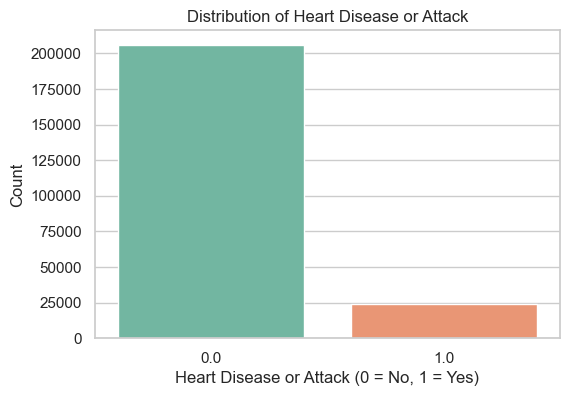

In [6]:
# Target variable distribution
target_counts = df['HeartDiseaseorAttack'].value_counts()
target_pct = df['HeartDiseaseorAttack'].value_counts(normalize=True) * 100
print("Target Variable Distribution (HeartDiseaseorAttack):")
for val, count, pct in zip(target_counts.index, target_counts.values, target_pct.values):
    label = "Heart Disease/Attack" if val == 1.0 else "No Heart Disease/Attack"
    print(f"{label}: {count} ({pct:.2f}%)")

# Plot target distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='HeartDiseaseorAttack', data=df, palette='Set2')
plt.title('Distribution of Heart Disease or Attack')
plt.xlabel('Heart Disease or Attack (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.savefig('target_distribution.png', bbox_inches='tight')
plt.show()

### Key Insight:
The target variable is heavily imbalanced (~90.6% negative and ~9.4% positive). We must handle this imbalance during model training (using `class_weight='balanced'`) and focus on metrics like **Recall** and **F1-score** rather than accuracy.

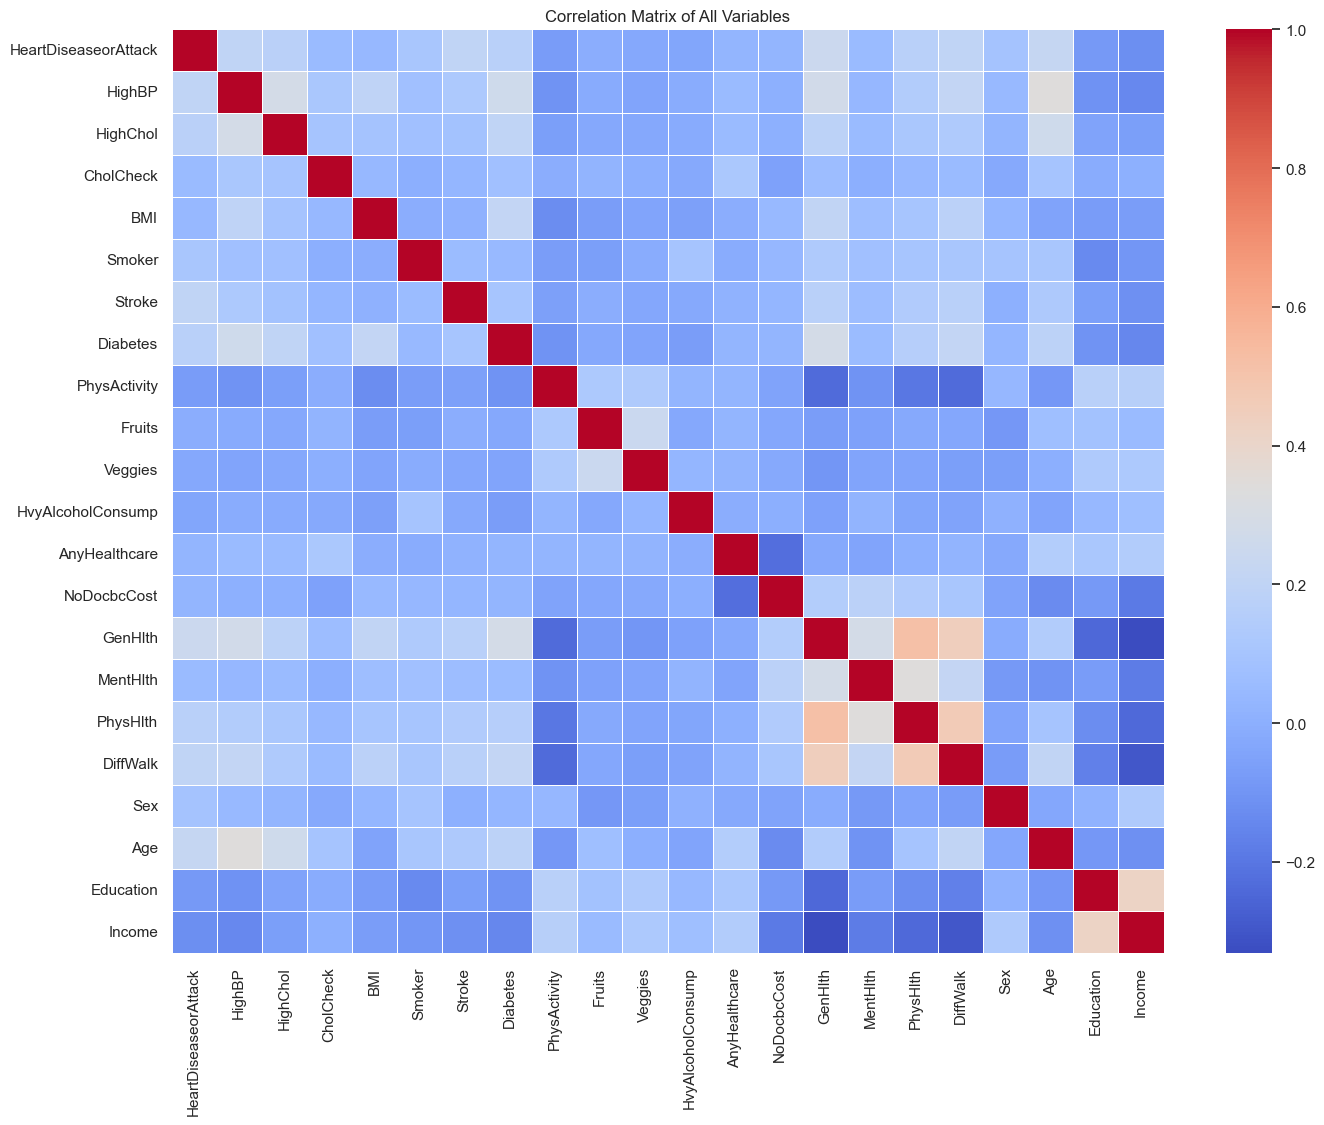

Correlation with HeartDiseaseorAttack (sorted):
HeartDiseaseorAttack    1.000000
GenHlth                 0.246411
Age                     0.223626
DiffWalk                0.202779
HighBP                  0.201271
Stroke                  0.198863
HighChol                0.176279
Diabetes                0.170816
PhysHlth                0.170473
Smoker                  0.105154
Sex                     0.089717
MentHlth                0.052756
CholCheck               0.049995
BMI                     0.039926
AnyHealthcare           0.025899
NoDocbcCost             0.022076
Fruits                 -0.007128
Veggies                -0.027330
HvyAlcoholConsump      -0.035453
PhysActivity           -0.073267
Education              -0.082466
Income                 -0.122908
Name: HeartDiseaseorAttack, dtype: float64


In [7]:
# Correlation matrix
plt.figure(figsize=(16, 12))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of All Variables')
plt.savefig('correlation_matrix.png', bbox_inches='tight')
plt.show()

# Top correlated features with target
print("Correlation with HeartDiseaseorAttack (sorted):")
print(corr_matrix['HeartDiseaseorAttack'].sort_values(ascending=False))

C:\Users\Manish\AppData\Local\Temp\ipykernel_19060\869779487.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='HighBP', y='HeartDiseaseorAttack', data=df, palette='viridis')


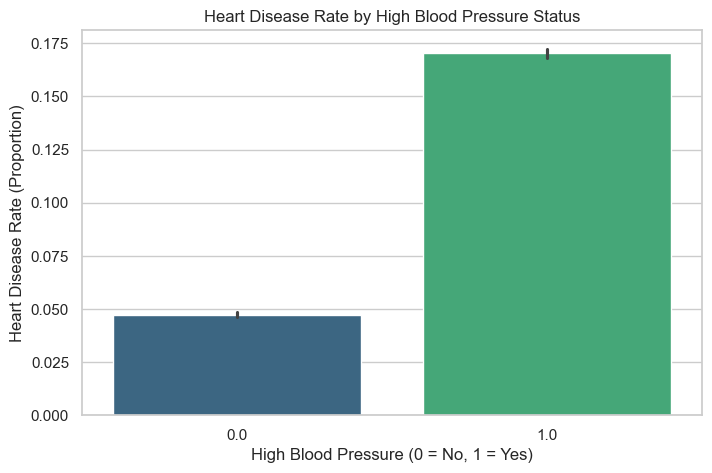

In [8]:
# Visualize relationship between HighBP and Heart Disease
plt.figure(figsize=(8, 5))
sns.barplot(x='HighBP', y='HeartDiseaseorAttack', data=df, palette='viridis')
plt.title('Heart Disease Rate by High Blood Pressure Status')
plt.xlabel('High Blood Pressure (0 = No, 1 = Yes)')
plt.ylabel('Heart Disease Rate (Proportion)')
plt.savefig('bp_vs_heart_disease.png', bbox_inches='tight')
plt.show()

C:\Users\Manish\AppData\Local\Temp\ipykernel_19060\3080857520.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='GenHlth', y='HeartDiseaseorAttack', data=df, palette='magma')


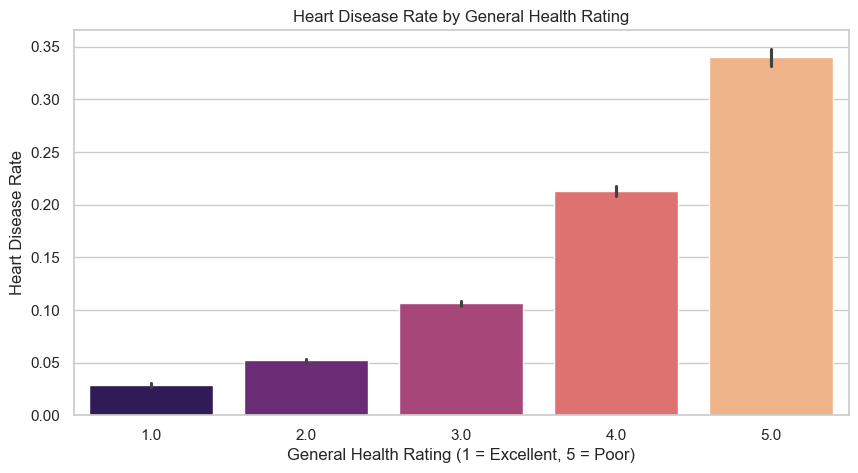

In [9]:
# Visualize relationship between General Health (GenHlth) and Heart Disease
# GenHlth: 1 = Excellent, 5 = Poor
plt.figure(figsize=(10, 5))
sns.barplot(x='GenHlth', y='HeartDiseaseorAttack', data=df, palette='magma')
plt.title('Heart Disease Rate by General Health Rating')
plt.xlabel('General Health Rating (1 = Excellent, 5 = Poor)')
plt.ylabel('Heart Disease Rate')
plt.savefig('health_vs_heart_disease.png', bbox_inches='tight')
plt.show()

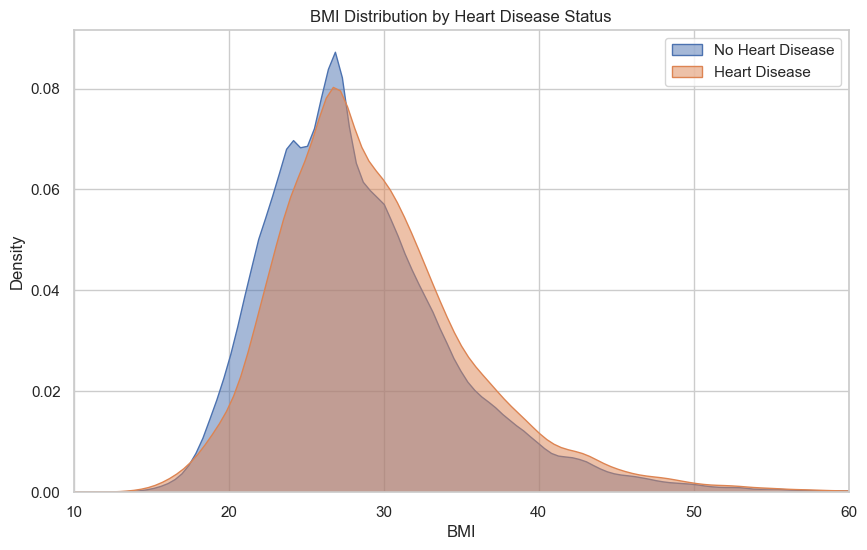

In [10]:
# Analyze BMI distribution for Heart Disease vs No Heart Disease
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df[df['HeartDiseaseorAttack'] == 0], x='BMI', fill=True, label='No Heart Disease', alpha=0.5)
sns.kdeplot(data=df[df['HeartDiseaseorAttack'] == 1], x='BMI', fill=True, label='Heart Disease', alpha=0.5)
plt.title('BMI Distribution by Heart Disease Status')
plt.xlabel('BMI')
plt.xlim(10, 60)
plt.legend()
plt.savefig('bmi_distribution.png', bbox_inches='tight')
plt.show()

## 3. Data Preprocessing & Split
Now, we split the data into training and testing sets, and standardize numerical variables (`BMI`, `MentHlth`, `PhysHlth`) using `StandardScaler`.

In [11]:
# Define features (X) and target (y)
X = df.drop('HeartDiseaseorAttack', axis=1)
y = df['HeartDiseaseorAttack']

# Train-Test Split (80% train, 20% test, stratify to maintain target ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

# Scale numerical columns: BMI, MentHlth, PhysHlth
num_cols = ['BMI', 'MentHlth', 'PhysHlth']
scaler = StandardScaler()

# Fit on training data and transform both training and testing sets
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

# Save the scaler for use in deployment
joblib.dump(scaler, 'scaler.joblib')
print("Scaler saved as scaler.joblib")

Training set size: (183824, 21)
Testing set size: (45957, 21)
Scaler saved as scaler.joblib


## 4. Model Training & Hyperparameter Tuning
We will perform hyperparameter tuning for both models to find the best configuration:
1. **Logistic Regression** tuned using `GridSearchCV`
2. **Random Forest Classifier** tuned using `RandomizedSearchCV` on a stratified subset of training data (for speed), then trained on the full training set.

In [12]:
# 1. Hyperparameter Tuning for Logistic Regression
print("Tuning Logistic Regression Hyperparameters using GridSearchCV...")
lr_param_grid = {
    'C': [0.01, 0.1, 1.0],
    'solver': ['liblinear', 'lbfgs']
}
lr_grid_search = GridSearchCV(
    estimator=LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    param_grid=lr_param_grid,
    cv=3,
    scoring='roc_auc',
    n_jobs=1
)
lr_grid_search.fit(X_train_scaled, y_train)

print(f"Best parameters for Logistic Regression: {lr_grid_search.best_params_}")
lr_model = lr_grid_search.best_estimator_

# Predictions
lr_preds = lr_model.predict(X_test_scaled)
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]

print("\n--- Tuned Logistic Regression Classification Report ---")
print(classification_report(y_test, lr_preds))
print(f"ROC-AUC Score: {roc_auc_score(y_test, lr_probs):.4f}")

Tuning Logistic Regression Hyperparameters using GridSearchCV...


Best parameters for Logistic Regression: {'C': 1.0, 'solver': 'lbfgs'}

--- Tuned Logistic Regression Classification Report ---
              precision    recall  f1-score   support

         0.0       0.97      0.73      0.83     41214
         1.0       0.25      0.78      0.38      4743

    accuracy                           0.74     45957
   macro avg       0.61      0.76      0.61     45957
weighted avg       0.89      0.74      0.79     45957

ROC-AUC Score: 0.8355


In [13]:
# 2. Hyperparameter Tuning for Random Forest using RandomizedSearchCV
# Since the dataset is large (~200,000 rows in training), we perform RandomizedSearchCV
# on a stratified 10% subset of training data to save time, then train the final model on full training data.
print("Tuning Random Forest Hyperparameters using RandomizedSearchCV...")

# Subsampling 10% of the training data
_, X_tune, _, y_tune = train_test_split(
    X_train_scaled, y_train, test_size=0.10, random_state=42, stratify=y_train
)
print(f"Subset size for hyperparameter tuning: {X_tune.shape}")

rf_param_dist = {
    'n_estimators': [50, 100, 150],
    'max_depth': [8, 12, 16],
    'min_samples_leaf': [3, 5, 7],
    'class_weight': ['balanced']
}

rf_random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=1),
    param_distributions=rf_param_dist,
    n_iter=5,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=1
)
rf_random_search.fit(X_tune, y_tune)

print(f"Best parameters found: {rf_random_search.best_params_}")

# Train the final Random Forest model on the FULL training set using the best parameters
print("\nTraining final Random Forest model on the full training set with best parameters...")
rf_model = RandomForestClassifier(**rf_random_search.best_params_, random_state=42, n_jobs=1)
rf_model.fit(X_train_scaled, y_train)

# Predictions
rf_preds = rf_model.predict(X_test_scaled)
rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]

print("\n--- Tuned Random Forest Classification Report ---")
print(classification_report(y_test, rf_preds))
print(f"ROC-AUC Score: {roc_auc_score(y_test, rf_probs):.4f}")

Tuning Random Forest Hyperparameters using RandomizedSearchCV...
Subset size for hyperparameter tuning: (18383, 21)


Best parameters found: {'n_estimators': 150, 'min_samples_leaf': 7, 'max_depth': 8, 'class_weight': 'balanced'}

Training final Random Forest model on the full training set with best parameters...



--- Tuned Random Forest Classification Report ---
              precision    recall  f1-score   support

         0.0       0.97      0.72      0.82     41214
         1.0       0.25      0.80      0.38      4743

    accuracy                           0.73     45957
   macro avg       0.61      0.76      0.60     45957
weighted avg       0.89      0.73      0.78     45957

ROC-AUC Score: 0.8336


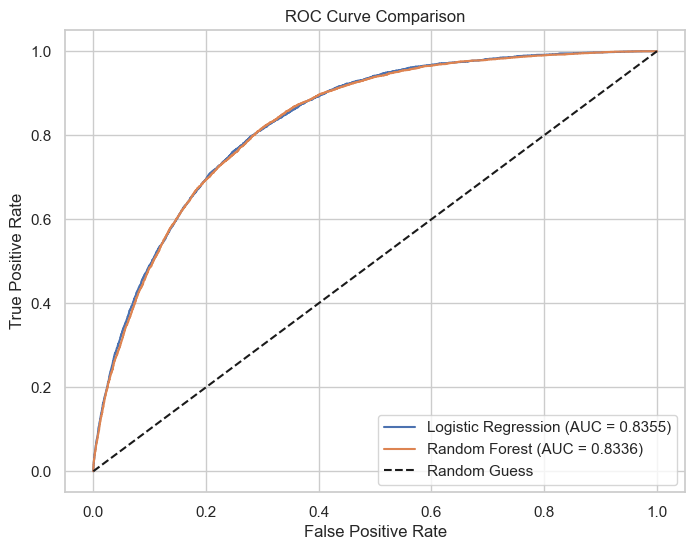

In [14]:
# Plot ROC Curves
plt.figure(figsize=(8, 6))
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)

plt.plot(lr_fpr, lr_tpr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, lr_probs):.4f})')
plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {roc_auc_score(y_test, rf_probs):.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.savefig('roc_curve_comparison.png', bbox_inches='tight')
plt.show()

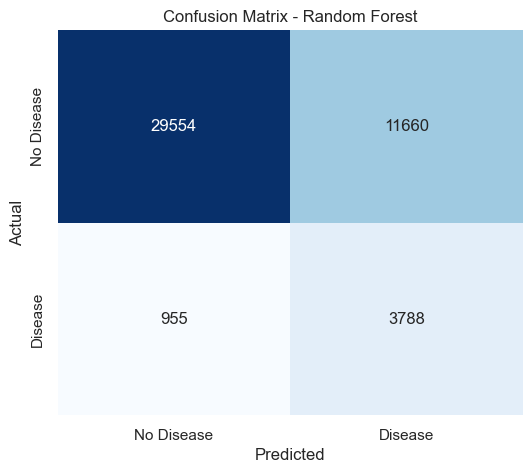

In [15]:
# Plot Confusion Matrix for Random Forest
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.savefig('confusion_matrix_rf.png', bbox_inches='tight')
plt.show()

C:\Users\Manish\AppData\Local\Temp\ipykernel_19060\3055474305.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rf_importances.values, y=rf_importances.index, palette='viridis')


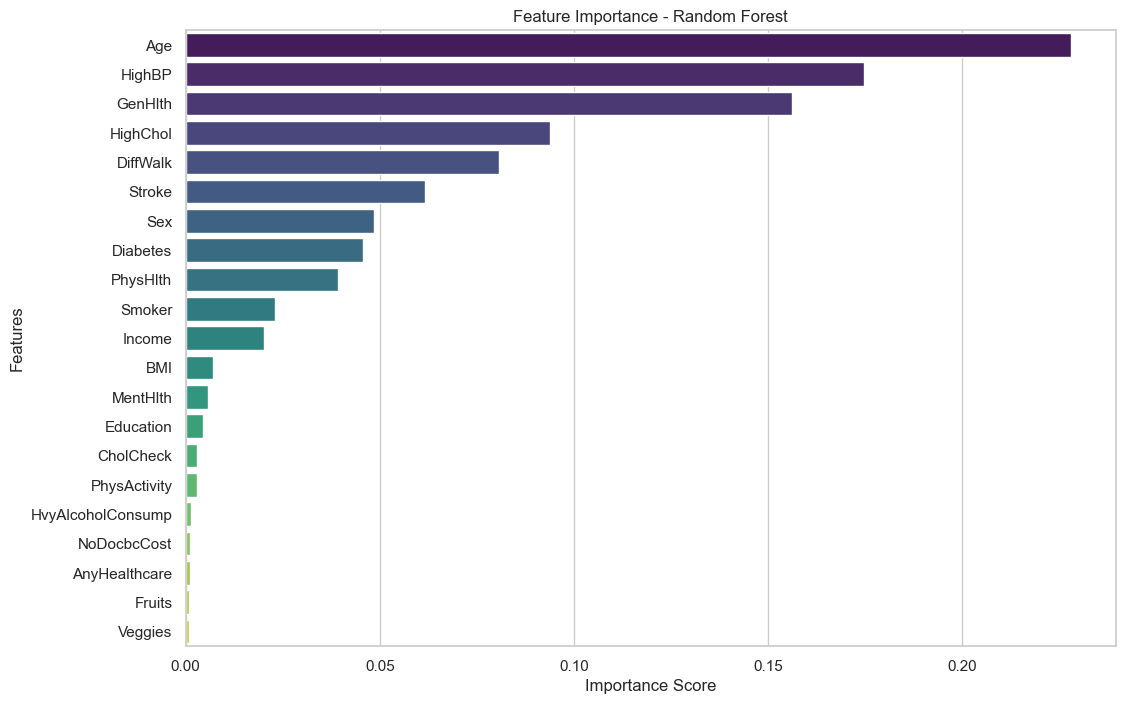

Top 10 features sorted by importance:
Age         0.228102
HighBP      0.174778
GenHlth     0.156239
HighChol    0.093785
DiffWalk    0.080603
Stroke      0.061642
Sex         0.048461
Diabetes    0.045679
PhysHlth    0.039208
Smoker      0.022953
dtype: float64


In [16]:
# Feature Importance from Random Forest
importances = rf_model.feature_importances_
feature_names = X.columns
rf_importances = pd.Series(importances, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x=rf_importances.values, y=rf_importances.index, palette='viridis')
plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.savefig('feature_importance.png', bbox_inches='tight')
plt.show()

print("Top 10 features sorted by importance:")
print(rf_importances.head(10))

## 5. Model Serialization
The Random Forest model performs better (higher ROC-AUC score and balanced classification report). We save this model for use in our Streamlit web application.

In [17]:
# Save the model
model_filename = 'heart_disease_model.joblib'
joblib.dump(rf_model, model_filename)
print(f"Model saved successfully to {model_filename}!")

Model saved successfully to heart_disease_model.joblib!
